# SakAI Final Demo
## Data collection

### 1. Start with fields where we know the crop

SakAI asks whether satellite images can help recognize **carrot, cabbage, and potato** in a new growing region. This part of the demo covers the first two steps: finding fields with known crops and collecting Sentinel-2 imagery for them.

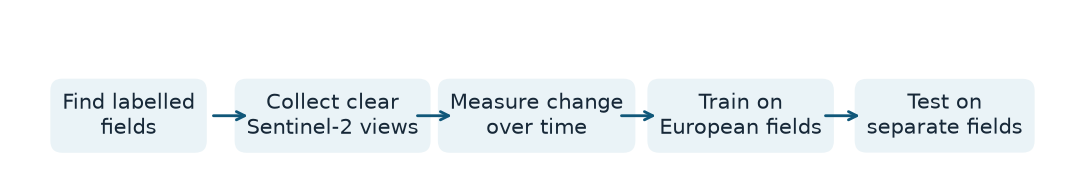

**Why** · We need field records that tell us what grew where, and satellite imagery that covers those same places.

[Full walkthrough](SakAI_crop_classification_walkthrough.ipynb) · [Project design](../docs/project_design.md)

### 2. Meet the datasets

**All development fields come from Europe**, mainly Spain, France, and the Netherlands. We collected separate fields for external testing. The star marks Paoay in Atok, Benguet, where we ultimately want to apply the work.

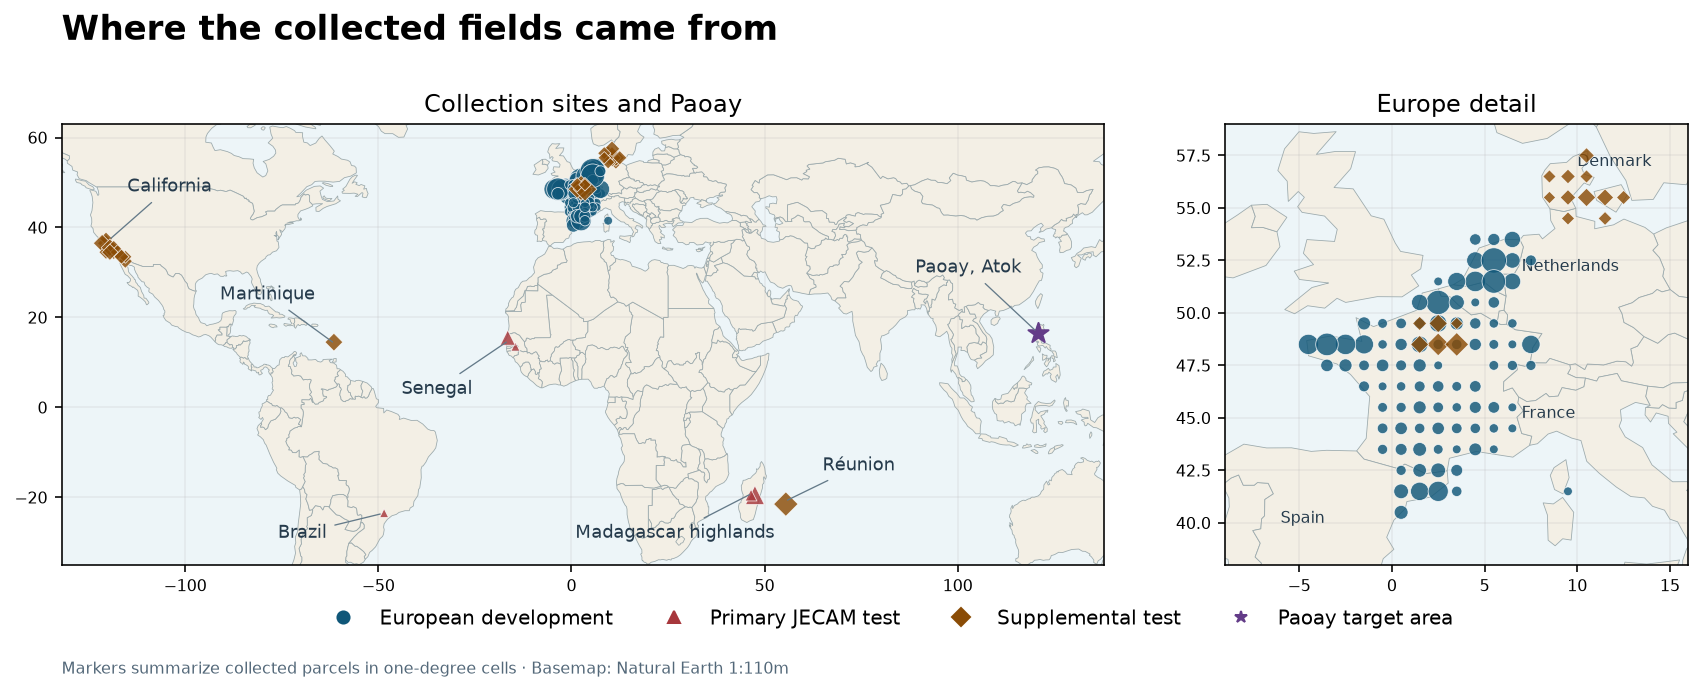

| Where | What it supplies |
| --- | --- |
| Spain, France, and the Netherlands | European development fields from Sen4AgriNet, FranceCrops, and EuroCrops |
| Madagascar’s tropical central highlands | JECAM fields with records for carrot, cabbage, and potato |
| Senegal and Brazil | Other JECAM collection sites |
| California, Denmark, Île-de-France, Martinique, and Réunion | Supplemental external collection sites |
| Paoay, Atok | Target area for future local checks |

**Why** · Madagascar gives us a tropical highland comparison with small fields and records of all three crops. It gives us a starting point for thinking about Paoay. Accuracy in Paoay still needs a local field test.

[Dataset register](../docs/classification_dataset_register.md) · [Saved collection inputs](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/source_inputs.json)

### 3. Use one kind of satellite imagery

We need **Sentinel-2 Level-2A surface reflectance** at the labelled fields over time. It measures how much light the ground reflects after accounting for the atmosphere. Repeated images show how the crop changes as it grows.

| Dataset | Imagery in or used by the source | How it differs from the input we need |
| --- | --- | --- |
| Sen4AgriNet | Multi-date Sentinel-2 imagery | **Same satellite.** We build half-month summaries with the same cloud rules and grid used for the other sources. |
| FranceCrops | Sentinel-2 Level-2A time series | **Same satellite and product level.** Our pipeline applies one cloud mask, grid, and half-month schedule across every source. |
| EuroCrops | Dutch parcel boundaries and crop declarations | **Field records only** in the release we used. We need to collect the Sentinel-2 time series separately. |
| CropHarvest JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** Our classifier uses a standardized Sentinel-2 optical time series. |
| CropHarvest non-JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** We use the same Sentinel-2 optical input as for JECAM. |
| California DWR | Crop surveys informed by aerial imagery, Landsat, and Sentinel | **Imagery supports the survey mapping.** We need repeated Sentinel-2 measurements at the surveyed fields. |
| Denmark Marker | Declared field boundaries and crop codes | **Field records only** in the release we used. We need to collect the Sentinel-2 time series separately. |

We use the **field locations listed in each dataset** to query Google Earth Engine for Sentinel-2 imagery from the reference year. The crop labels tell us what was recorded at those locations.

**Why** · One imagery archive and a shared set of processing rules give every field comparable measurements. We can skip downloading and harmonizing separate imagery packages.

[Sen4AgriNet benchmark](https://arxiv.org/abs/2204.00951) · [FranceCrops dataset](https://huggingface.co/datasets/saget-antoine/francecrops) · [EuroCrops parcel data](https://essd.copernicus.org/articles/18/4075/2026/essd-18-4075-2026.html) · [CropHarvest benchmark](https://github.com/nasaharvest/cropharvest) · [California DWR survey methods](https://resources.ca.gov/-/media/DWR-Website/Web-Pages/Programs/Water-Use-And-Efficiency/Land-And-Water-Use/Land-Use-Surveys/Files/Land-Use-Program-Frequently-Asked-Questions.pdf) · [Denmark Marker release](https://landbrugsgeodata.fvm.dk/) · [Project collection rules](../docs/collection.md)

### 4. Queue it, disconnect, collect it later

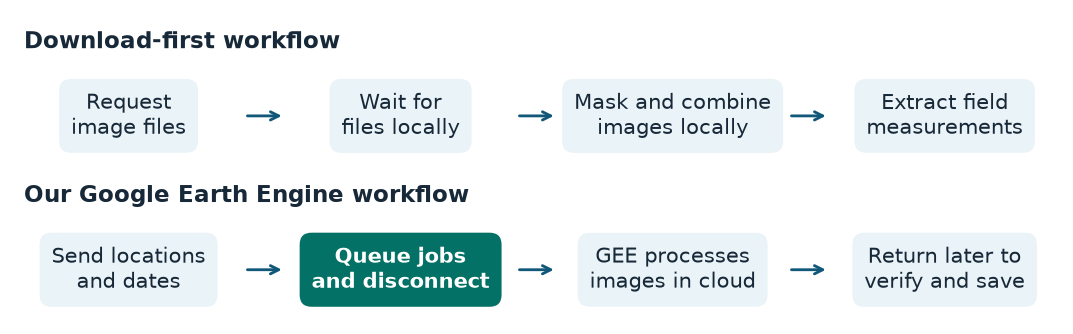

**The workaround** · Submit the jobs and save their task IDs. Once Earth Engine accepts them, the laptop can disconnect while the jobs wait in the queue and run in the cloud. Come back online later to find the finished jobs, retrieve and verify the outputs, and save them locally.

### The Earth Engine settings that matter

| Setting | What we used | Why |
| --- | --- | --- |
| Satellite imagery | Harmonized Sentinel-2 Level-2A surface reflectance | Every field starts with the same kind of measurement of light reflected from the ground. |
| Date range | The full year in the crop record | Each request covers the recorded year. We can choose the growing months later using the saved imagery. |
| Cloud and shadow filter | Keep pixels with a cloud probability below 40%. Also remove cloud shadows and pixels with missing cloud scores. | Clouds and shadows hide the crop and can distort how green it looks. |
| Pixel grid | Line up the bands on the same 10 m grid | Each band describes the same location. Lining them up adds no new detail to the coarser bands. |
| Half-month summary | Combine images taken on the same day, then take the middle value (median) of the clear readings across days in each half-month | It gives us 24 regular time slots for the year and reduces the effect of an unusually high or low reading. |

**Why** · The laptop is free while Earth Engine works, and we can resume from saved task IDs. We transfer the results needed for the fields and can reuse the verified archive for later analysis.

[Collection guide](../docs/collection.md) · [Imagery settings](../docs/methodology.md#candidate-sampling-and-imagery) · [Saved imagery formats](../docs/reference/transport.md)

### 5. How many fields did we collect?

A **parcel** is one reference field group. The chart and table count the collected parcels in the saved imagery audit input, by source and crop.

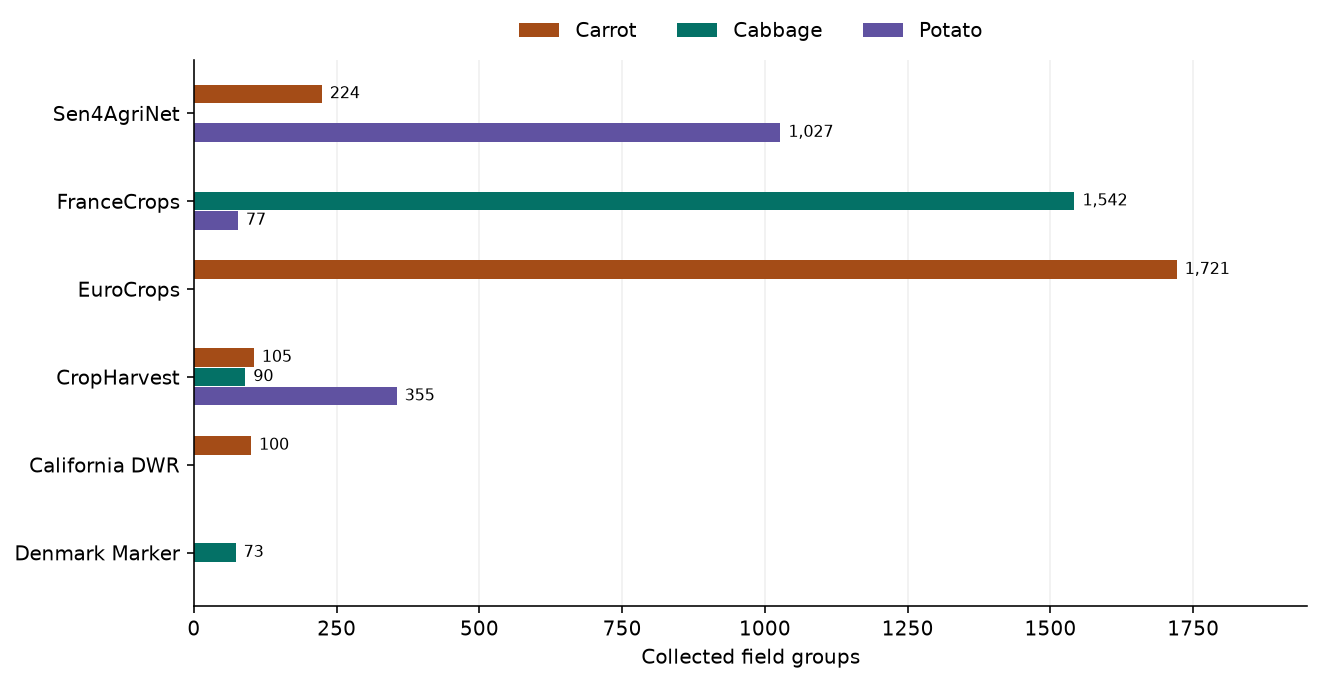

| Source | Carrot fields | Cabbage fields | Potato fields | Total fields |
| --- | ---: | ---: | ---: | ---: |
| Sen4AgriNet | 224 | 0 | 1,027 | 1,251 |
| FranceCrops | 0 | 1,542 | 77 | 1,619 |
| EuroCrops | 1,721 | 0 | 0 | 1,721 |
| CropHarvest | 105 | 90 | 355 | 550 |
| California DWR | 100 | 0 | 0 | 100 |
| Denmark Marker | 0 | 73 | 0 | 73 |
| **Total** | **2,150** | **1,705** | **1,459** | **5,314** |

**Why** · Sources cover different crops. EuroCrops adds many carrot fields, FranceCrops supplies all the European development cabbage, and Sen4AgriNet supplies most of the European development potato. A large total can still leave a crop concentrated in just one source.

[Saved collection input profile](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/reference_profile.csv) · [Collection guide](../docs/collection.md)

### 6. Collect imagery for the reference year

A Dutch carrot field declared in **2021** tells us where to look and which year to request. We query Earth Engine for Sentinel-2 imagery at that field during 2021.

**Why** · The same field can grow different crops from one year to the next. Using the reference year ties the imagery request to the year covered by the crop record.

[Collection guide](../docs/collection.md)

## Preprocessing

### 7. Turn satellite views into half-month summaries

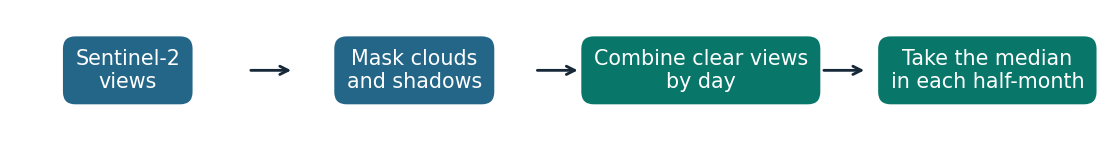

Earth Engine masks clouds, shadows, and invalid readings. It combines usable views taken on the same day, then takes the **middle value (median)** across days within each half-month. The annual archive has **24 expected half-month slots**. A cloudy slot can still have few or zero usable pixels.

**Why** · The median reduces the impact of unusually high or low readings. Regular time slots let us compare the same field across the year.

[Imagery processing rules](../docs/methodology.md#candidate-sampling-and-imagery)

### 8. Which half-months have enough clear imagery?

Start with this FranceCrops cabbage field tile. The two panels show real Sentinel-2 half-month images of the same spot. The grid outlines the **10 pixels selected for sampling**. Hatched cells had no usable reading in that half-month.

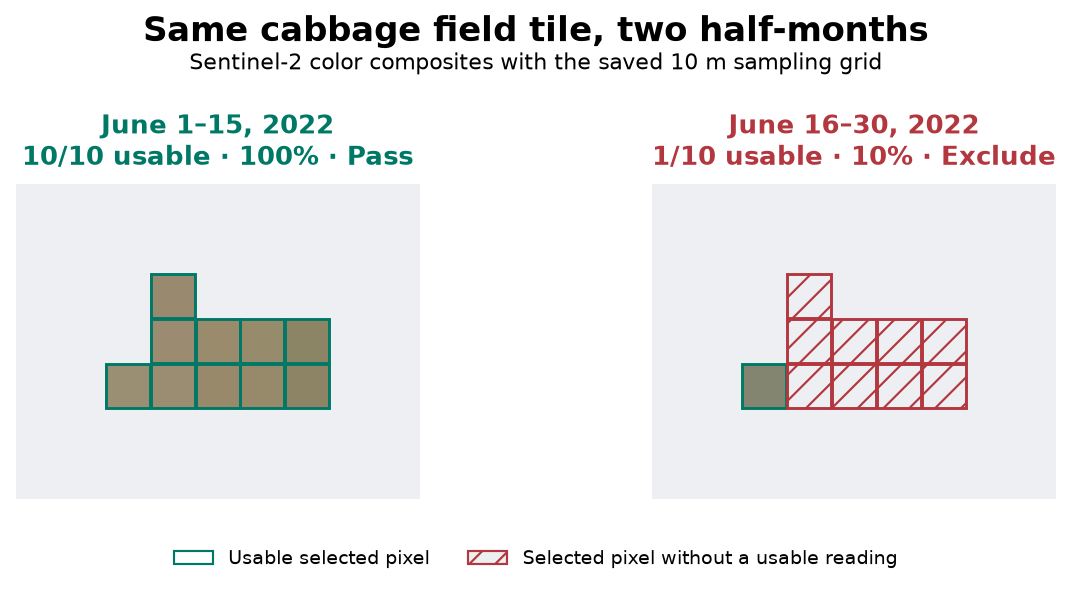

**Where the 10 m buffer comes in** · For FranceCrops, we move the field boundary **10 m inward** during collection, before choosing which pixel centers to sample. Along the edge, a pixel can include a road or a neighboring crop. Sampling farther inside reduces that mix. The audit reuses this saved set of pixels in each half-month. Sen4AgriNet uses its existing crop-mask cells.

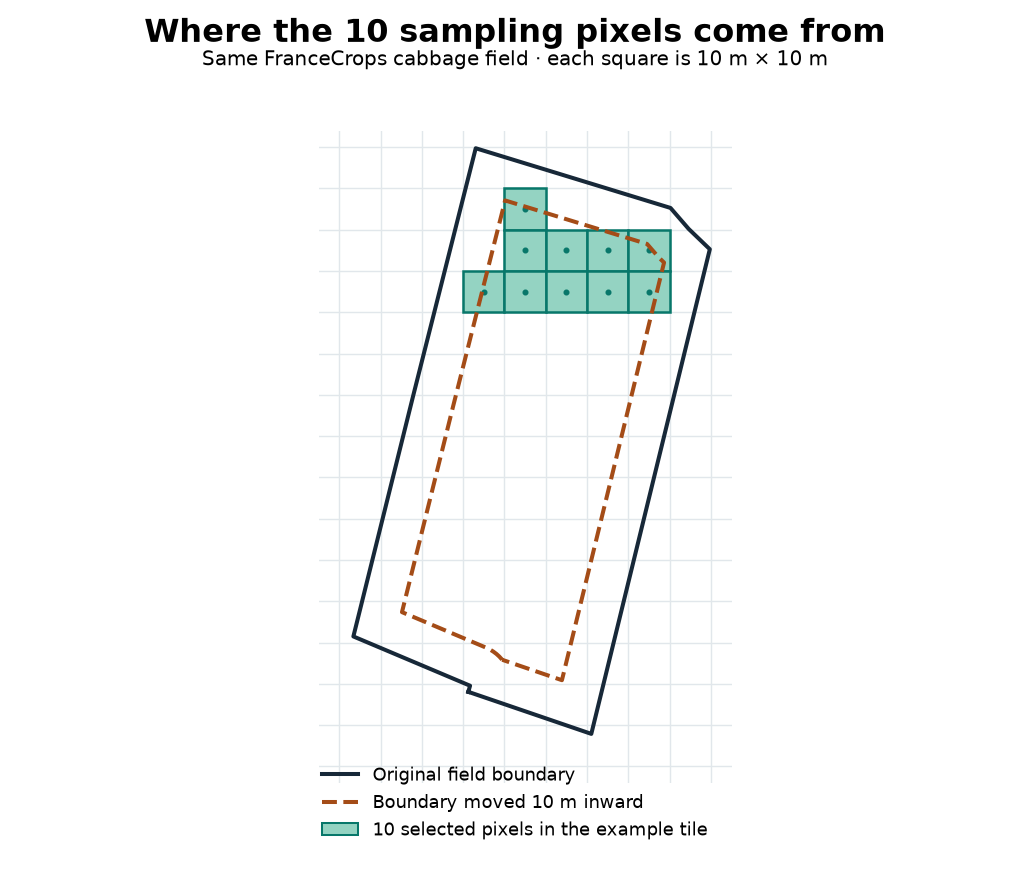

The green squares are the sample pixels in the **same tile shown in the June images**. Their centers lie inside the buffered boundary. They are the 10 pixels used as the denominator for the 80% check in both half-months.

A selected pixel is **usable** if it has at least one clear observation during the half-month and valid readings in all required bands.

**How we decide** · Divide usable pixels by selected pixels. Here, **8 of 10** are needed to reach 80%. June 1–15 passes with **10 of 10**. June 16–30 falls short with **1 of 10**, so we exclude that entire half-month for this tile, including the one usable pixel.

**What Part 9 does with that result** · The fixed May–August window needs all eight half-months. June 16–30 leaves this tile with only **seven passing intervals**, so it contributes no complete pixels to that window. The green-up window is checked against its own eight dates.

| Across the run | Tile × half-month records |
| --- | ---: |
| Before the 80% check · all audited | 172,200 |
| After the check · passed | 131,928 |
| Below 80% · excluded from window inputs | 40,272 |

A **tile × half-month** is one tile checked for one time slot. The excluded count includes **23,665 saved intervals with zero usable pixels**. There were **0 missing composites**.

**Why** · Part 8 checks one half-month at a time. Part 9 uses those results to find pixels with usable readings in all eight half-months of a window.

<details>
<summary>Other checks from this run</summary>

- The records with loss diagnostics contained **59,564,089 clear pixel-dates** and **132,275,610 pixel-dates lost to clouds or shadows**. A pixel-date is one selected pixel on one satellite observation date. Loss diagnostics were unavailable for **11,664 tile-intervals**.
- The external footprint overlap screen recorded **zero exclusions**.

</details>

[Sampling and buffer rules](../docs/methodology.md#candidate-sampling-and-imagery) · [Quality audit](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/quality.json) · [Observation loss by half-month](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/observation_loss_by_half_month.csv) · [Footprint overlap report](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/test_overlap_exclusions.json)

## Feature engineering

### 9. Turn satellite readings into features and choose the windows

A **feature** is one number the model can use. We build features for each selected pixel in each half-month that passes Part 8.

### Read the five bands

A **band** measures light in one part of the spectrum. The archive stores the band readings as scaled numbers. We multiply them by **0.0001** to get reflectance before calculating the indices.

| Band | Light measured |
| --- | --- |
| **B3** | Green |
| **B4** | Red |
| **B5** | Red-edge, between red and near-infrared |
| **B8** | Near-infrared |
| **B11** | Shortwave-infrared |

### Combine bands into vegetation indices

| Index | How we calculate it | What it helps describe |
| --- | --- | --- |
| **NDVI** | (B8 − B4) ÷ (B8 + B4) | How green the vegetation looks. The rise in NDVI helps guide green-up timing. |
| **NDRE** | (B8 − B5) ÷ (B8 + B5) | Vegetation changes using the red-edge band. |
| **NDMI** | (B8 − B11) ÷ (B8 + B11) | Moisture-related changes in vegetation. |
| **SAVI** | 1.5 × (B8 − B4) ÷ (B8 + B4 + 0.5) | Greenness adjusted for the influence of exposed soil. The final export adds this index. |

**Worked example** · One EuroCrops carrot pixel from this run, **May 1–15, 2021**. The band readings are rounded here.

| B3 | B4 | B5 | B8 | B11 |
| ---: | ---: | ---: | ---: | ---: |
| 0.0836 | 0.1003 | 0.1135 | 0.1346 | 0.1626 |

Plug B8 and B4 into NDVI: **(0.1346 − 0.1003) ÷ (0.1346 + 0.1003) ≈ 0.146**. Here are all four index values for that pixel and half-month.

| NDVI | NDRE | NDMI | SAVI |
| ---: | ---: | ---: | ---: |
| 0.146 | 0.085 | -0.094 | 0.070 |

### Keep eight half-months in order

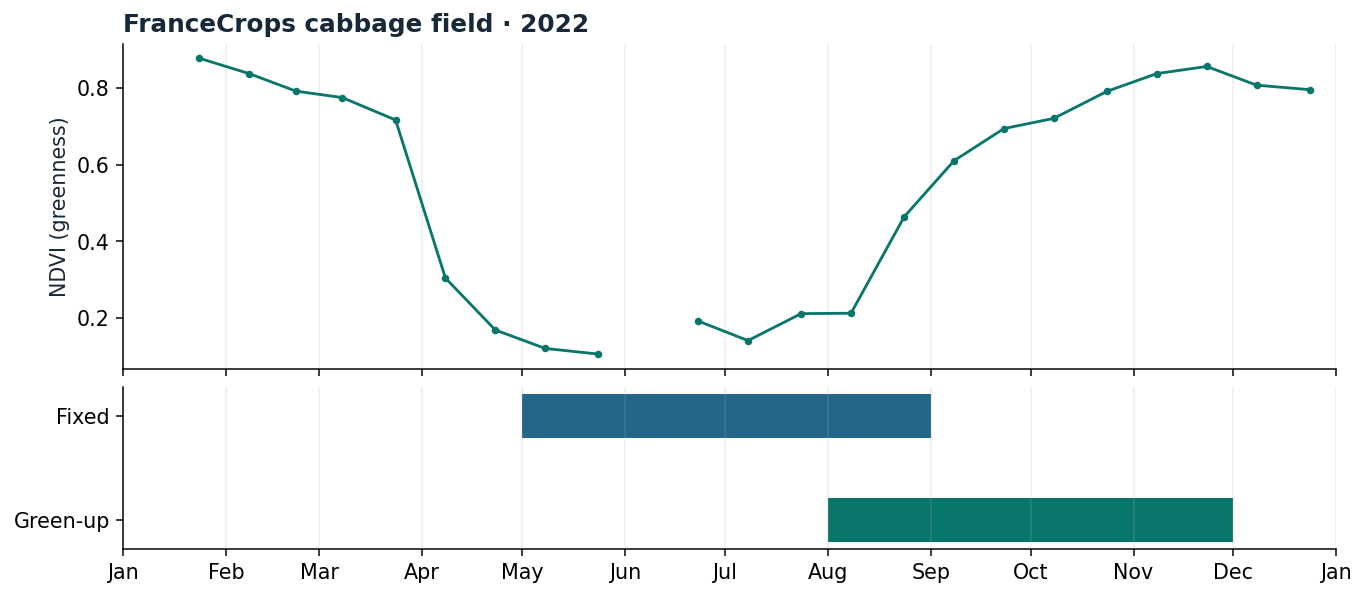

The **fixed** window uses May through August everywhere. The **green-up** method looks for a sustained rise in satellite greenness and starts the window in the estimated onset month. The chart shows the saved half-month NDVI values for the example field. The detector uses the available daily observations to estimate timing. Both windows span **four months and eight half-month slots**.

To qualify as green-up, the rise must hold across later observations and be supported by a rise in NDRE. We try qualifying windows in date order. If the earliest one has no pixel with complete readings, we check the next one.

For each candidate window, a pixel needs **5 bands + 3 indices in all 8 half-months**, or **64 base values**. A missing value or failed interval makes the sequence incomplete for that window. After matching and splitting, the final export adds **one SAVI value per half-month**, giving **72 inputs per pixel per window**. The inputs stay in time order, from the first half-month to the eighth.

**Why** · The bands describe what the satellite sees. The indices help us read greenness and moisture-related changes. Keeping eight sets of readings in order lets the model use how the field changes across the season.

[Feature formulas](../docs/methodology.md#classifier-features) · [Saved windows](../pipeline_outputs/preprocessing/external_t4tyh93t/windows/seasons/estimated_windows.csv) · [Saved NDVI series](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/timelines/composite_timelines.csv)

### 10. Match the usable pixel locations

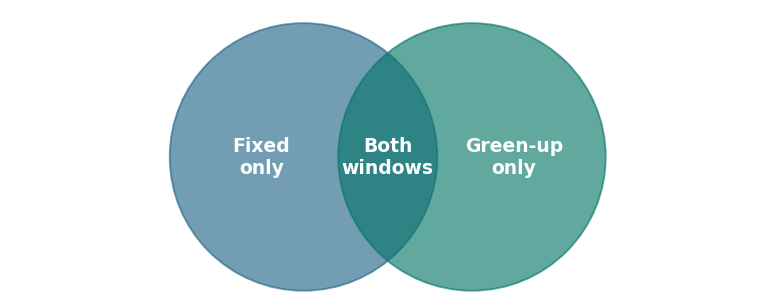

A matched pixel has complete measurements for the **same field and exact pixel location** under both windows. Before matching or applying the cap, we remove locations shared by different development fields from both fields’ records within that method. The run flagged **605 shared locations for fixed** and **121 for green-up**. After matching, we keep up to **20 pixels per field** in the matched set.

| Complete windows before matching and capping · all inputs | Field groups | Pixel windows |
| --- | ---: | ---: |
| Fixed | 1,914 | 461,823 |
| Green-up | 568 | 156,262 |

| Final export | Development fields | Development pixels | All exported external fields | All exported external pixels |
| --- | ---: | ---: | ---: | ---: |
| Matched · both windows | 274 | 4,553 | 181 | 2,124 |

The first table counts all complete windows. The matched export counts the shared locations after those checks and the pixel cap. Part 19 shows the final reporting scope for the supplemental checks.

**Why** · Using the same locations for both methods helps isolate the effect of changing the dates.

[Complete-window counts](../pipeline_outputs/preprocessing/external_t4tyh93t/windows/window_counts.csv) · [Usable development counts](../pipeline_outputs/preprocessing/external_t4tyh93t/features/usable_samples.csv) · [External coverage](../pipeline_outputs/preprocessing/external_t4tyh93t/features/test_population_coverage.csv) · [Shared-location exclusions](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/development_overlap_exclusions.json)

### 11. Split the development fields

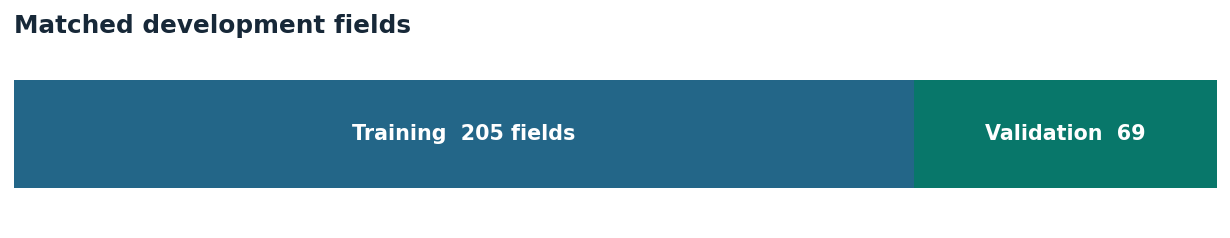

After matching, the pipeline aims for **75% training and 25% validation** on development fields. It balances the split by **crop** and by **which window methods have usable data**, giving priority to the matched fields. It locks one assignment per field and uses it across both methods. The **external test stays separate** throughout.

**Why** · Keeping all pixels from a field together lets validation check the model on fields it has never seen.

[Saved development assignments](../pipeline_outputs/preprocessing/external_t4tyh93t/features/development_split.json)

### 12. See what’s ready for training and testing

The final export stores **72 inputs per pixel**. Each of the eight half-months contributes five bands and four indices. The final export adds **SAVI**, a greenness measure adjusted for the influence of exposed soil, to the three indices introduced in Part 9.

| Matched set | Carrot fields | Cabbage fields | Potato fields | Total fields | Pixels |
| --- | ---: | ---: | ---: | ---: | ---: |
| Training | 68 | 50 | 87 | 205 | 3,401 |
| Validation | 23 | 17 | 29 | 69 | 1,152 |
| Primary JECAM | 37 | 11 | 35 | 83 | 345 |
| All exported external fields (includes JECAM) | 100 | 31 | 50 | 181 | 2,124 |

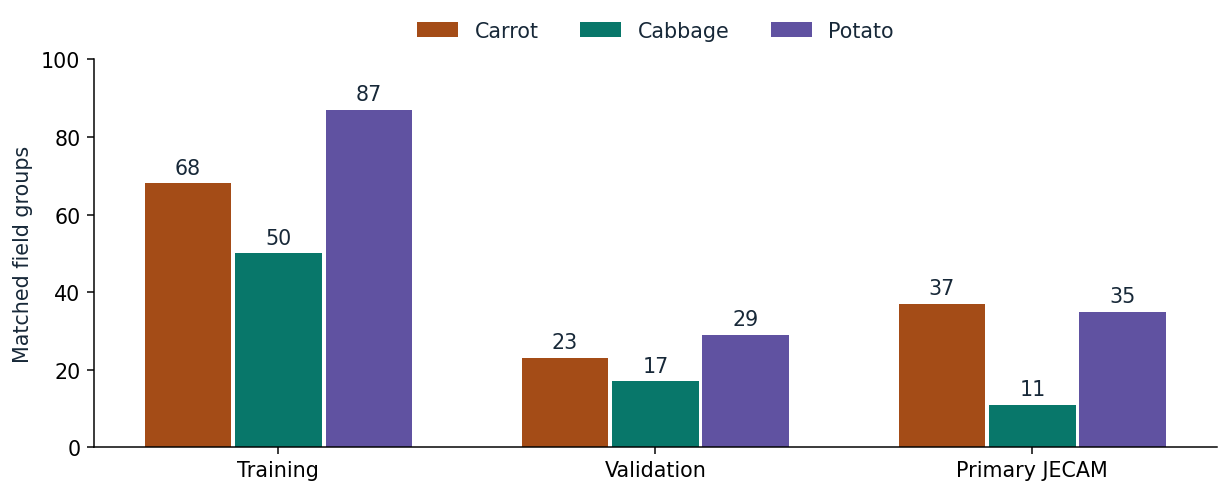

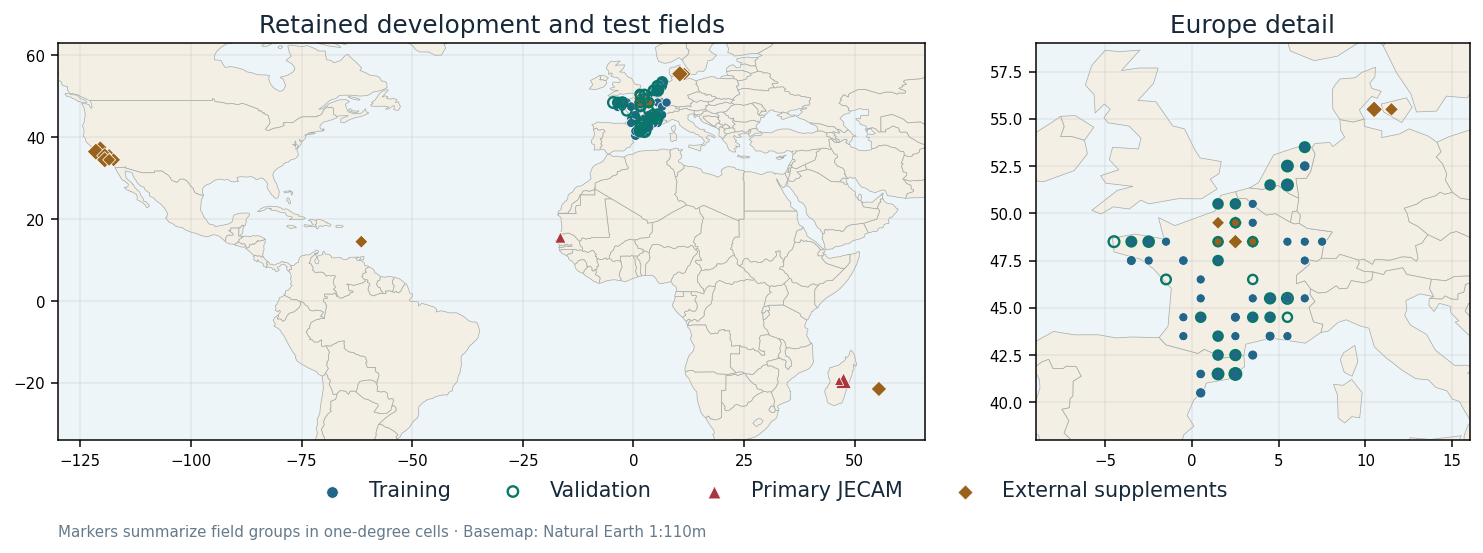

The external totals and map show the preprocessing export. Part 19 shows which supplements are included in the reported evaluation.

### Where we fell short of the sample targets

The targets are **60 fields and 1,200 pixels per crop for training**, and **20 fields and 400 pixels per crop for validation and external testing**. The table shows each missed target in the matched sets. A zero means that target was met.

| Matched set | Crop | Fields short | Pixels short |
| --- | --- | ---: | ---: |
| Training | Carrot | 0 | 3 |
| Training | Cabbage | 10 | 212 |
| Validation | Carrot | 0 | 24 |
| Validation | Cabbage | 3 | 87 |
| Primary JECAM | Carrot | 0 | 285 |
| Primary JECAM | Cabbage | 9 | 307 |
| Primary JECAM | Potato | 0 | 263 |
| All exported external fields | Potato | 0 | 34 |

For example, primary JECAM cabbage had **11 fields and 93 pixels**, leaving it **9 fields and 307 pixels short**. These targets help us assess dataset coverage.

**Why** · The total can hide small crop groups. The primary JECAM test has **11 cabbage fields**, compared with **37 carrot** and **35 potato**. With fewer cabbage examples, each field has more influence on that crop’s result. The map shows how much of the geographic coverage came from European development fields.

[Final usable samples](../pipeline_outputs/preprocessing/external_t4tyh93t/features/usable_samples.csv) · [Test campaign coverage](../pipeline_outputs/preprocessing/external_t4tyh93t/features/test_population_coverage.csv)

## Training and validation

### 13. Load the matched inputs

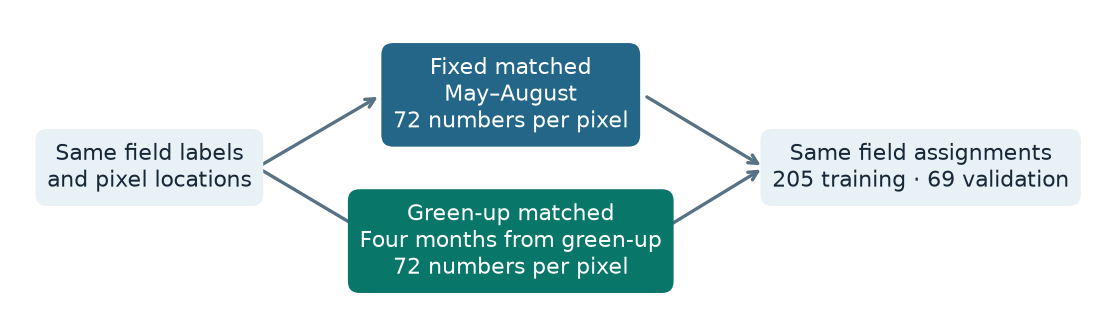

We start with the **72 numbers per pixel** from Part 12 and the recorded crop for each field. We train one model with **fixed May–August** readings and one with **green-up-aligned** readings. Both use the same pixel locations and locked assignments, with **205 fields for training** and **69 for validation**.

**Why** · Comparing the same locations and field assignments makes it easier to see what changes when we use different imagery months.

[Saved field assignments](../pipeline_outputs/preprocessing/external_t4tyh93t/features/development_split.json)

### 14. Train the Random Forests

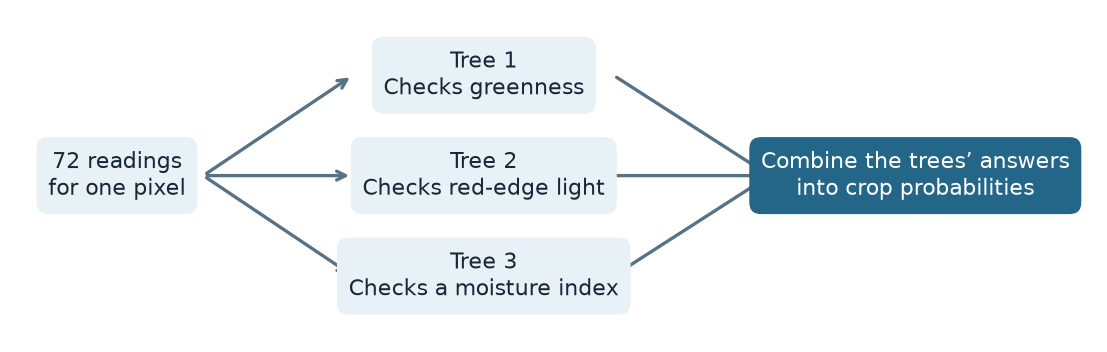

A **decision tree** asks a series of yes/no questions about a pixel’s readings. One might ask whether greenness is above a certain value in a given half-month. Each Random Forest combines **1,000 trees** to estimate how likely the pixel is to be carrot, cabbage, or potato. The picture shows three example trees.

During fitting, we give each crop the **same total weight**, then divide that weight equally among the fields of that crop. All pixels from a field share its weight.

**Why** · Different trees can learn different patterns. Weighting keeps crops and fields with more pixels from having extra influence simply because they supplied more readings.

[Random Forest settings and weighting](../docs/methodology.md#model-selection-and-scoring)

### 15. Validate one field at a time

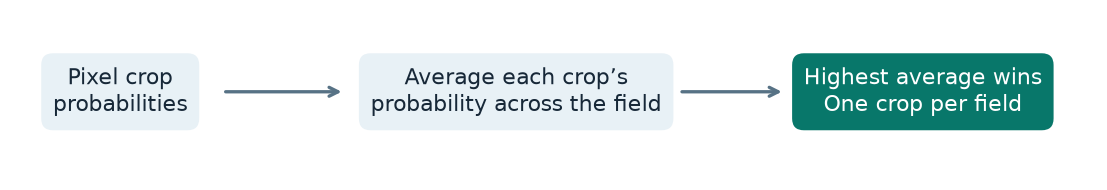

For each validation field, the model gives each pixel three crop probabilities. We **average the probabilities for each crop across the field’s pixels**, then pick the crop with the highest average. We compare that prediction with the crop recorded for the field.

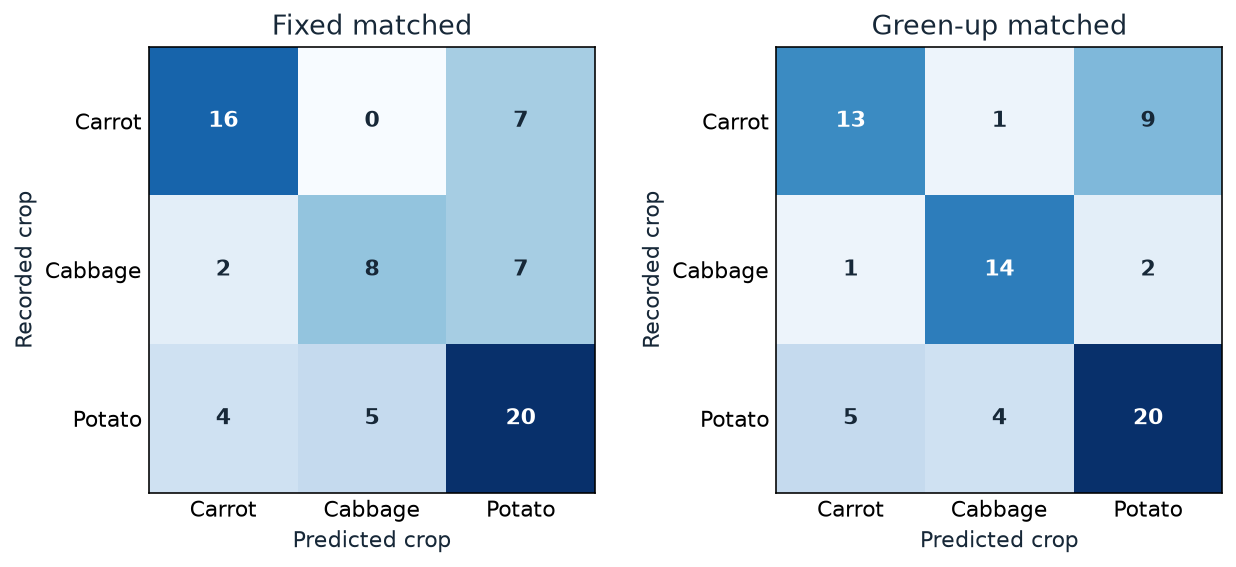

Both models were scored on the same **69 validation fields**. Read across a row to see where fields of that crop were classified. For example, the fixed model correctly classified **8 of 17 cabbage fields**, and green-up correctly classified **14 of 17**.

**Why** · One prediction per field gives a small field the same weight as a large field in the validation counts. The matrix shows which mistakes changed when we used a different window.

[Fixed matched validation record](../pipeline_outputs/training/run_3f6675c72535/validation/fixed_matched/model_manifest.json) · [Green-up matched validation record](../pipeline_outputs/training/run_3f6675c72535/validation/aligned_matched/model_manifest.json)

### 16. Compare validation scores and freeze both models

**Macro-F1** is the average of the three crop F1 scores. A crop’s F1 reflects both how often the model finds that crop and how often its predictions for that crop are right.

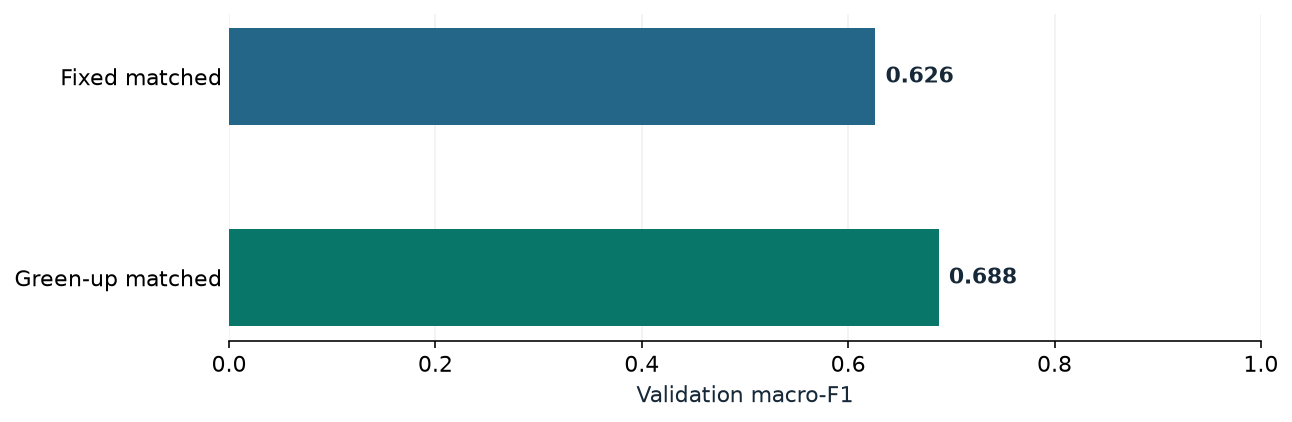

| Validation metric | Fixed matched | Green-up matched |
| --- | ---: | ---: |
| Carrot | 0.711 | 0.619 |
| Cabbage | 0.533 | 0.778 |
| Potato | 0.635 | 0.667 |
| **Macro-F1** | **0.626** | **0.688** |
| **Overall accuracy** | 63.8% (44/69) | 68.1% (47/69) |

Green-up scored higher overall on these validation fields. Its cabbage F1 improved, while fixed scored higher for carrot. Both models used a **minimum leaf size of 2**, meaning a tree needs at least two training samples in each final group. We **froze both fitted models** with their settings and feature order.

**Why** · Macro-F1 gives each crop equal weight. Freezing saves the exact models behind these validation results so we can reproduce the comparison.

[Fixed matched frozen manifest](../pipeline_outputs/training/run_3f6675c72535/models/fixed_matched/model_manifest.json) · [Green-up matched frozen manifest](../pipeline_outputs/training/run_3f6675c72535/models/aligned_matched/model_manifest.json)

## External testing

### 17. Pair the frozen models with the held-out data

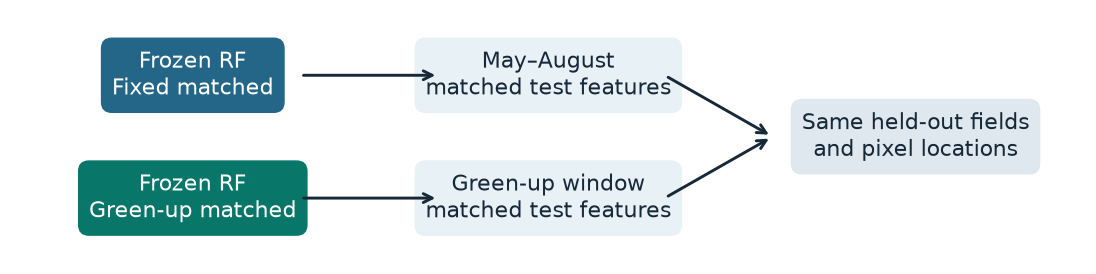

The **Fixed-Matched Random Forest** receives May–August readings. The **Green-up Matched Random Forest** receives readings from the four months selected using green-up. Both test inputs come from the same preprocessing run used for training. We use the frozen trees and settings from Part 16.

The test keeps the same pixel locations for both models. For each field, we average the pixel probabilities for each crop and choose the crop with the highest average.

**Why** · Holding the fields and locations constant gives both models the same external test. We can compare how the two sets of imagery dates perform on that test.

[Matched test run receipt](../pipeline_outputs/testing/run_1ba733a7a49c/scores.json)

### 18. Evaluate on primary JECAM fields

Both models were scored on **83 fields and 345 matched pixels**. The baseline predicts **potato for every field**, because potato was the most common crop among the matched training fields.

| Field-level result | Fixed matched | Green-up matched | Potato baseline |
| --- | ---: | ---: | ---: |
| Overall accuracy | 38.6% (32/83) | 38.6% (32/83) | 42.2% (35/83) |
| Macro-F1 | 0.379 | 0.260 | 0.198 |

| Crop | Fields | Pixels | Fixed F1 | Green-up F1 |
| --- | ---: | ---: | ---: | ---: |
| Carrot | 37 | 115 | 0.506 | 0.041 |
| Cabbage | 11 | 93 | 0.552 | 0.167 |
| Potato | 35 | 137 | 0.080 | 0.571 |

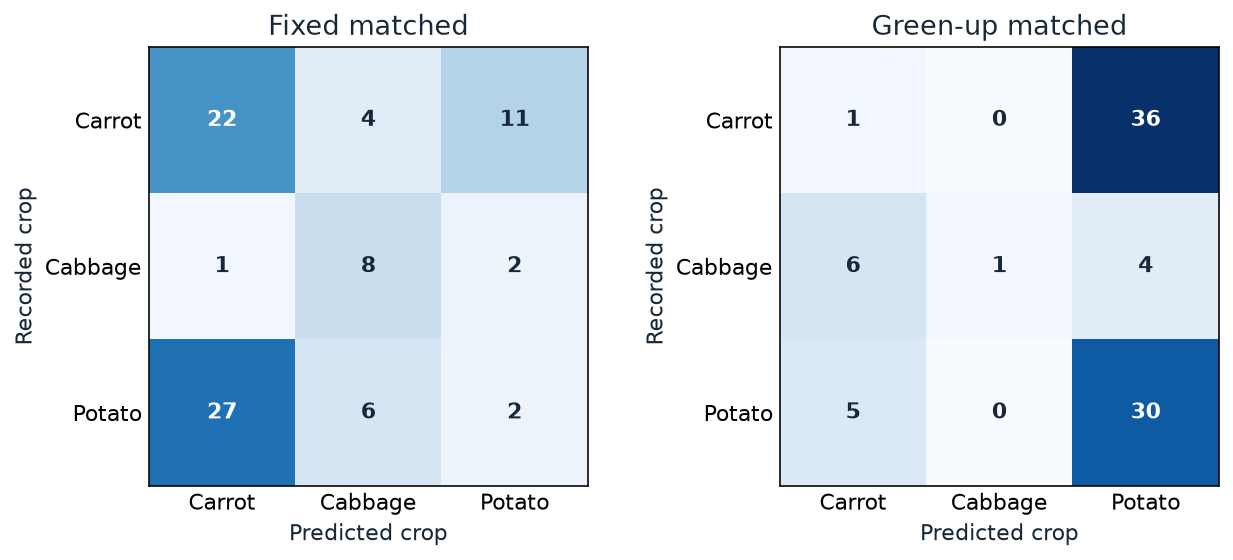

Both models got **32 of 83 fields** right. Fixed recognized more carrot and cabbage fields, and green-up recognized more potato fields. Both beat the potato baseline on macro-F1. Both fell short of the project’s **0.50 macro-F1 target**.

**Why** · Accuracy counts how many fields we got right. Macro-F1 gives each crop equal weight, and the confusion matrices show which crops the models mixed up.

[Primary JECAM scores](../pipeline_outputs/testing/run_1ba733a7a49c/reports/test_scores.json) · [Training-majority baseline](../pipeline_outputs/testing/run_1ba733a7a49c/reports/majority_baseline.json)

### 19. Check the supplemental regions separately

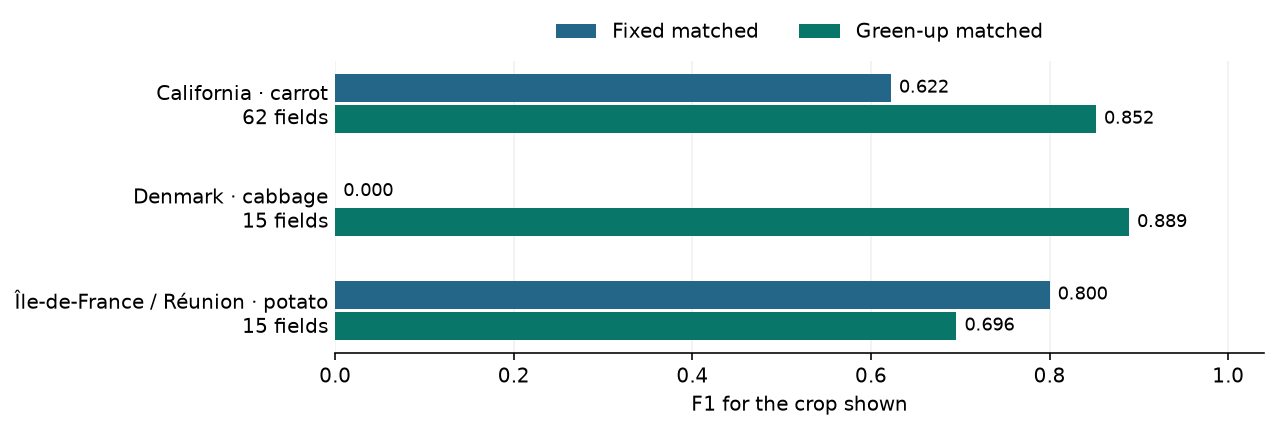

| Supplemental campaign | Crop | Fields | Pixels | Fixed F1 | Green-up F1 |
| --- | --- | ---: | ---: | ---: | ---: |
| California DWR · California | Carrot | 62 | 1,218 | 0.622 | 0.852 |
| Denmark Marker · Denmark | Cabbage | 15 | 264 | 0.000 | 0.889 |
| CropHarvest · Île-de-France / Réunion | Potato | 15 | 229 | 0.800 | 0.696 |

Each reported supplement has one target crop, so we show the F1 for that crop. We revised the reporting scope after reviewing the original scores. The archive keeps the non-JECAM CropHarvest carrot and cabbage predictions.

**Combined geographic check** · Pooling primary JECAM with these three supplements gives **175 fields**. Macro-F1 is **0.356** for fixed and **0.563** for green-up. Fixed leads on primary JECAM, while green-up leads in this combined pool.

**Why** · The locations and crop mix differ. Looking at each campaign helps us understand how that mix affects the combined score.

[Revised supplemental scores](../pipeline_outputs/testing/run_1ba733a7a49c_revised_scope_xnw3lrlu/matched_supplemental_scores.json)

### 20. Explain the limits and what we could improve

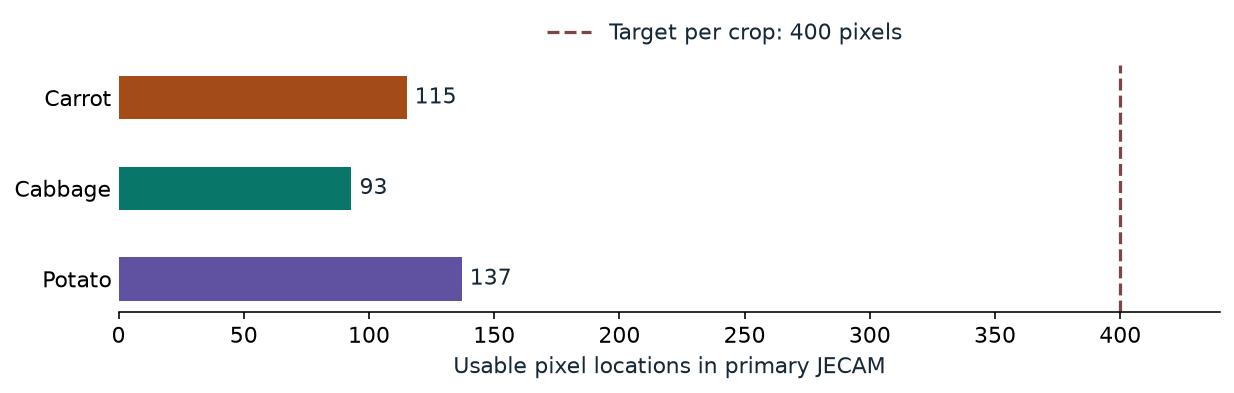

| Limitation | What it means here | What would help next |
| --- | --- | --- |
| **Temporal correspondence** | A reference year ties imagery to the crop record. The fixed calendar and the satellite-detected green-up can still cover different parts of a crop cycle. | Collect dated records of when the crop was in the field so future studies can check whether the imagery covers that period. |
| **Imagery coverage** | JECAM had **115 carrot, 93 cabbage, and 137 potato pixels** after matching. All three fell below the target of 400 pixels. | Collect more independent labelled fields in areas with enough clear observations and plan coverage checks before testing. |
| **Class imbalance** | JECAM had **11 cabbage fields**, compared with 37 carrot and 35 potato. A few fields can change cabbage F1 substantially. | Add independently labelled cabbage fields across more sites and years. |
| **Geographic transfer** | Madagascar provides a tropical highland comparison. Performance also varied across the other campaigns. | Test on independent Paoay field records before claiming local accuracy. |

**Why** · The external results show where each approach helped or struggled. Better timing records and more independent fields would give us a stronger check of whether those patterns repeat elsewhere.

[Saved diagnostics](../pipeline_outputs/testing/run_1ba733a7a49c/reports/diagnostics/results.md) · [Paoay field observations](../docs/paoay_workflow.md#field-observations)

## Experiments

### Baseline Random Forest training

We trained **Fixed-Matched RF** and **Aligned-Matched RF (green-up)** on the same **205 development training fields**. Both use 72 inputs per pixel from the same matched locations. The imagery dates differ. See Part 14 for the training setup.

### Baseline validation

We evaluated both models on the same **69 validation fields**. Part 15 shows the confusion matrices, and Part 16 shows per-crop F1 and the overall comparison.

| Validation metric | Fixed-Matched RF | Aligned-Matched RF |
| --- | ---: | ---: |
| Macro-F1 | 0.626 | 0.688 |
| Carrot F1 | 0.711 | 0.619 |
| Cabbage F1 | 0.533 | 0.778 |
| Potato F1 | 0.635 | 0.667 |
| Overall accuracy | 63.8% (44/69) | 68.1% (47/69) |

### Exploratory improvement experiments

Every row uses the current **205 matched training fields** and the same **69 locked validation fields**. The scores are **macro-F1 across the three crops**, using one prediction per field.

| Experiment | What changed | Fixed matched | Aligned matched |
| --- | --- | ---: | ---: |
| Baseline RF | 72 interval inputs | 0.626 | 0.688 |
| Shape only | 48 changes, slopes, and other shape measurements | 0.609 | 0.634 |
| Intervals + shape | 72 interval inputs plus 48 shape measurements | 0.604 | 0.694 |
| Bands only | 40 band readings | 0.652 | 0.685 |
| Indices only | 32 vegetation index readings | 0.662 | 0.634 |
| One half-month | 9 inputs from the fourth half-month | 0.576 | 0.621 |
| RF tuning | Selected in training folds: leaf size 4 (fixed), max depth 12 (aligned) | 0.612 | 0.699 |
| RBF SVM | 72 inputs, fixed settings | 0.656 | 0.655 |
| XGBoost | 72 inputs, fixed settings | 0.675 | 0.667 |
| Field-median RF | 72 median measurements per field | 0.626 | 0.669 |

We chose the RF tuning settings using five geographically grouped folds within training. The SVM and XGBoost used one preset each. The single half-month check used the fourth slot in each window. These are validation comparisons for ideas to investigate further. The external comparison below labels the two exploratory variants separately.

[Validation macro-F1 results](../pipeline_outputs/training/run_81de4b6717e9/validation_macro_f1.csv) · [Experiment settings and predictions](../pipeline_outputs/training/run_81de4b6717e9/validation_details.json) · [Run receipt](../pipeline_outputs/training/run_81de4b6717e9/matched_validation_experiments.json)

### External testing

We scored the two **frozen baseline models** and the two **exploratory variants** on the same **83 JECAM fields**.

| Window | Baseline Random Forest macro-F1 | Exploratory model | Exploratory macro-F1 |
| --- | ---: | --- | ---: |
| Fixed matched | 0.379 | XGBoost | 0.320 |
| Green-up matched | 0.260 | Tuned Random Forest | 0.258 |

Both variants scored higher than their baselines on validation and lower on JECAM. Part 18 gives the primary baseline results, and Part 19 shows the supplemental campaigns separately. [Exploratory JECAM scores](../pipeline_outputs/testing/run_f34706fce06b/jecam_macro_f1.json)

JECAM was **held out from fitting and validation** in the current run. Earlier experiments had already examined this benchmark, and some changes were informed by those results. A fresh, untouched test would use independent fields that had never been used to guide any of those decisions.

### Error analysis and limitations

| Limitation | What we would collect or check next |
| --- | --- |
| **Temporal mismatch** | Collect dated crop records to check whether the imagery window covers the time the crop was growing. |
| **Crop imbalance** | Add independent cabbage fields. Primary JECAM has 11 cabbage fields, compared with 37 carrot and 35 potato. |
| **Imagery gaps** | Look for gaps in clear observations during the crop cycle and expand the pool of fields with complete imagery. |
| **Geographic transfer** | Collect independent, dated field records in Paoay to measure performance there. |

**Why** · The baseline comparison shows what happened on the fields we evaluated. The exploratory work gives us ideas to check on fresh data.